Raw dataset
      ↓
Define X and y
      ↓
Reserve final test data
      ↓
Create training and validation data
      ↓
Build preprocessing
      ↓
Establish a simple majority baseline
      ↓
Train SGD Classifier
      ↓
Train Decision Tree Classifier
      ↓
Evaluate on validation data
      ↓
Compare initial models

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "manufacturing_6G_dataset.csv"
)

figures_dir = project_root / "figures"
figures_dir.mkdir(exist_ok=True)

df = pd.read_csv(dataset_path)

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"]
)

print("Dataset shape:", df.shape)

Dataset shape: (100000, 13)


In [3]:
X = df.drop(
    columns=[
        "Efficiency_Status",
        "Timestamp",
        "Machine_ID"
    ]
)

y = df["Efficiency_Status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

X shape: (100000, 10)
y shape: (100000,)

Input columns:
['Operation_Mode', 'Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Production_Speed_units_per_hr', 'Predictive_Maintenance_Score', 'Error_Rate_%']


In [4]:
print(y.value_counts())

print()

print(
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Efficiency_Status
Low       77825
Medium    19189
High       2986
Name: count, dtype: int64

Efficiency_Status
Low       77.82
Medium    19.19
High       2.99
Name: proportion, dtype: float64


In [5]:
X_development, X_test, y_development, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print(
    "Development set:",
    X_development.shape
)

print(
    "Final test set:",
    X_test.shape
)

Development set: (80000, 10)
Final test set: (20000, 10)


In [6]:
def class_distribution(labels):

    return (
        labels
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


distribution_comparison = pd.DataFrame({
    "Original": class_distribution(y),
    "Development": class_distribution(
        y_development
    ),
    "Test": class_distribution(y_test)
})

distribution_comparison

,Original,Development,Test
Efficiency_Status,,,
Low,77.82,77.82,77.82
Medium,19.19,19.19,19.19
High,2.99,2.99,2.99


In [7]:
X_train, X_validation, y_train, y_validation = (
    train_test_split(
        X_development,
        y_development,
        test_size=0.20,
        random_state=42,
        stratify=y_development
    )
)

print(
    "Training set:",
    X_train.shape
)

print(
    "Validation set:",
    X_validation.shape
)

print(
    "Final test set:",
    X_test.shape
)

Training set: (64000, 10)
Validation set: (16000, 10)
Final test set: (20000, 10)


In [8]:
numerical_features = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Predictive_Maintenance_Score",
    "Error_Rate_%"
]

categorical_features = [
    "Operation_Mode"
]

print(
    "Numerical features:",
    len(numerical_features)
)

print(
    "Categorical features:",
    len(categorical_features)
)

Numerical features: 9
Categorical features: 1


In [9]:
print(
    X_train["Operation_Mode"]
    .value_counts()
)

Operation_Mode
Active         44909
Idle           12807
Maintenance     6284
Name: count, dtype: int64


In [10]:
df[numerical_features].agg(
    ["min", "max"]
).T

,min,max
Temperature_C,30.000138,89.998979
Vibration_Hz,0.100011,4.999974
Power_Consumption_kW,1.500183,9.999889
Network_Latency_ms,1.000025,49.999917
Packet_Loss_%,0.000026,4.999975
Quality_Control_Defect_Rate_%,0.000449,9.999900
Production_Speed_units_per_hr,50.000375,499.996768
Predictive_Maintenance_Score,0.000003,0.999978
Error_Rate_%,0.000112,14.999869


In [11]:
sgd_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

sgd_preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

In [12]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

tree_preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

In [13]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(
    X_train,
    y_train
)

dummy_predictions = dummy_model.predict(
    X_validation
)

dummy_accuracy = accuracy_score(
    y_validation,
    dummy_predictions
)

dummy_macro_f1 = f1_score(
    y_validation,
    dummy_predictions,
    average="macro"
)

print(
    "Dummy Accuracy:",
    round(dummy_accuracy, 4)
)

print(
    "Dummy Macro F1:",
    round(dummy_macro_f1, 4)
)
print("dummy_predictions:", dummy_predictions.shape[0])

Dummy Accuracy: 0.7782
Dummy Macro F1: 0.2918
dummy_predictions: 16000


In [14]:
sgd_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            sgd_preprocessor
        ),
        (
            "model",
            SGDClassifier(
                random_state=42,
                max_iter=2000
            )
        )
    ]
)

sgd_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, de

In [15]:
sgd_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U6](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Operation_Mode','Temperature_C','Vibration_Hz',..., 'Production_Speed_units_per_hr','Predictive_Maintenance_Score', 'Error_Rate_%']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifie

In [16]:
sgd_predictions = sgd_pipeline.predict(
    X_validation
)

print(
    "First 10 predictions:"
)

print(
    sgd_predictions[:10]
)

print(
    "\nFirst 10 actual values:"
)

print(
    y_validation.iloc[:10].values
)

First 10 predictions:
['Low' 'Low' 'Medium' 'Low' 'Low' 'Low' 'Low' 'Low' 'Medium' 'Low']

First 10 actual values:
<StringArray>
['Low', 'Low', 'Medium', 'Medium', 'Low', 'Low', 'Low', 'Low', 'Medium',
 'Low']
Length: 10, dtype: str


In [17]:
def evaluate_model(
    model_name,
    y_true,
    y_pred
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    }

In [18]:
sgd_results = evaluate_model(
    "SGD Classifier",
    y_validation,
    sgd_predictions
)

pd.DataFrame(
    [sgd_results]
).round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,SGD Classifier,0.9031,0.898,0.7256,0.784,0.8995


In [19]:
print(
    classification_report(
        y_validation,
        sgd_predictions,
        labels=[
            "Low",
            "Medium",
            "High"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       0.93      0.97      0.95     12452
      Medium       0.77      0.71      0.74      3070
        High       1.00      0.50      0.67       478

    accuracy                           0.90     16000
   macro avg       0.90      0.73      0.78     16000
weighted avg       0.90      0.90      0.90     16000



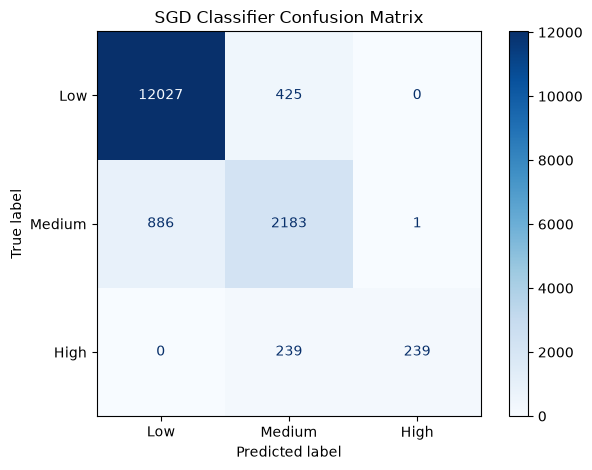

In [20]:
class_order = [
    "Low",
    "Medium",
    "High"
]

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    sgd_predictions,
    labels=class_order,
    cmap="Blues"
)

plt.title(
    "SGD Classifier Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "sgd_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
tree_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            tree_preprocessor
        ),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

tree_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, de

In [22]:
tree_pipeline.fit(
    X_train,
    y_train
)

print(
    "Decision Tree trained successfully."
)

Decision Tree trained successfully.


In [23]:
tree_predictions = tree_pipeline.predict(
    X_validation
)

In [24]:
tree_results = evaluate_model(
    "Decision Tree",
    y_validation,
    tree_predictions
)

pd.DataFrame(
    [tree_results]
).round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Decision Tree,1.0,1.0,1.0,1.0,1.0


In [25]:
print(
    classification_report(
        y_validation,
        tree_predictions,
        labels=class_order,
        zero_division=0
    )
)

              precision    recall  f1-score   support

         Low       1.00      1.00      1.00     12452
      Medium       1.00      1.00      1.00      3070
        High       1.00      1.00      1.00       478

    accuracy                           1.00     16000
   macro avg       1.00      1.00      1.00     16000
weighted avg       1.00      1.00      1.00     16000



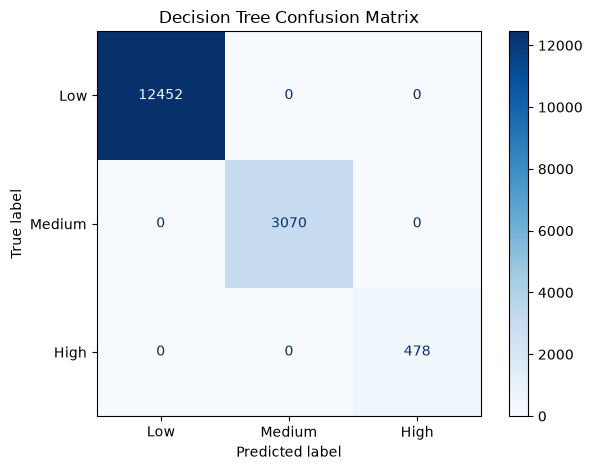

In [26]:
ConfusionMatrixDisplay.from_predictions(
    y_validation,
    tree_predictions,
    labels=class_order,
    cmap="Blues"
)

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "decision_tree_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
trained_tree = (
    tree_pipeline
    .named_steps["model"]
)

print(
    "Tree depth:",
    trained_tree.get_depth()
)

print(
    "Number of leaves:",
    trained_tree.get_n_leaves()
)

Tree depth: 4
Number of leaves: 5


In [28]:
dummy_results = evaluate_model(
    "Majority Baseline",
    y_validation,
    dummy_predictions
)

In [29]:
results = pd.DataFrame([
    dummy_results,
    sgd_results,
    tree_results
])

results.round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Majority Baseline,0.7782,0.2594,0.3333,0.2918,0.6812
1,SGD Classifier,0.9031,0.8980,0.7256,0.7840,0.8995
2,Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000


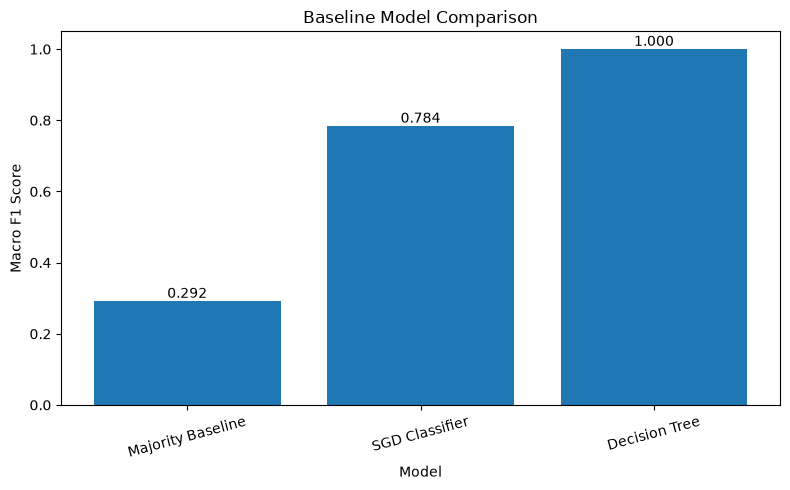

In [30]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    results["Model"],
    results["Macro F1"]
)

plt.title(
    "Baseline Model Comparison"
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Macro F1 Score"
)

plt.ylim(
    0,
    1.05
)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        height,
        f"{height:.3f}",
        ha="center",
        va="bottom"
    )

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
print(
    "Final test observations:",
    len(X_test)
)

print(
    "Final test set has NOT been used "
    "for model evaluation."
)

Final test observations: 20000
Final test set has NOT been used for model evaluation.


# Preprocessing and Baseline Classification Conclusions

## Data Splitting

The dataset was divided into separate training, validation, and final test datasets.

Approximately:

`64%` Training

`16%` Validation

`20%` Final Test

Stratified splitting was used to preserve the original distribution of the `Low`, `Medium`, and `High` efficiency classes.

The final test dataset was reserved and was not used during notebook 3 model development.

## Input Features and Target

The target variable is:

`Efficiency_Status`

The initial model inputs exclude:

`Timestamp`

`Machine_ID`

The remaining manufacturing sensor, operational, network, production, maintenance, and quality variables were used as candidate input features.

## Preprocessing

The numerical and categorical features require different preprocessing.

The numerical features were standardized for the SGD Classifier using `StandardScaler`.

The categorical `Operation_Mode` feature was transformed using `OneHotEncoder`.

A `ColumnTransformer` and Scikit learn `Pipeline` were used so that preprocessing and model prediction are performed consistently.

The Decision Tree used the original numerical scales because tree based models do not require feature standardization.

No missing value imputation was required because notebook 1 confirmed that the dataset contains no missing values.

## Majority Class Baseline

A majority class baseline was created using a classifier that always predicts the most common target class.

Because approximately 77.8% of the observations belong to the `Low` efficiency class, this simple baseline can obtain relatively high accuracy despite failing to identify the `Medium` and `High` classes.

This demonstrates why accuracy alone is not sufficient for evaluating this dataset.

## SGD Classifier

The SGD Classifier was trained as the first machine learning classification baseline.

Its performance was evaluated using:

`Accuracy`

`Macro Precision`

`Macro Recall`

`Macro F1`

`Weighted F1`

`Classification Report`

`Confusion Matrix`

Macro metrics were emphasized because they give equal importance to the Low, Medium, and High classes despite the strong class imbalance.

## Decision Tree Classifier

A Decision Tree Classifier was trained using the same training and validation datasets.

Decision Trees are particularly relevant to this dataset because they can learn threshold based decision rules.

The notebook 1 analysis showed that `Production_Speed_units_per_hr` and `Error_Rate_%` can reproduce the `Efficiency_Status` target through simple threshold conditions.

Therefore, strong Decision Tree performance should be interpreted in the context of this known target structure.

## Initial Model Comparison

The majority baseline, SGD Classifier, and Decision Tree Classifier were compared using the same validation dataset.

The comparison focused primarily on Macro F1 rather than accuracy alone.

The confusion matrices were also analysed to determine whether the models correctly identify all three efficiency classes, especially the minority `High` efficiency class.

## Conclusion

The complete machine learning workflow is now able to accept raw manufacturing observations, preprocess numerical and categorical features, train classification models, and generate multiclass predictions.

The final test dataset remains untouched.

The next stage will introduce Random Forest classification and use cross validation to evaluate the stability and generalization of the models across multiple data subsets.

In notebook 4 will compare:

`SGD Classifier`

`Decision Tree Classifier`

`Random Forest Classifier`

using cross validation and appropriate multiclass evaluation metrics.